# 04 — Visualizations

Charts for the same SQLite data. Money plots skip budget or revenue of 0, same decision as in the pandas notebook. Other plots keep every movie.

I used Matplotlib and Seaborn. Plotly is in the Streamlit app, where the charts need to be interactive.


In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

conn = sqlite3.connect("data/tmdb.db")
movies = pd.read_sql("SELECT * FROM movies", conn)
genres = pd.read_sql("SELECT * FROM genres", conn)
movie_genres = pd.read_sql(
    "SELECT rowid, movie_id, genre_id FROM movie_genres ORDER BY rowid", conn
)
movies["release_date"] = pd.to_datetime(movies["release_date"])
movies["year"] = movies["release_date"].dt.year

valid = movies[(movies["budget"] > 0) & (movies["revenue"] > 0)].copy()
first_genre = (
    movie_genres.drop_duplicates("movie_id", keep="first")
    .merge(genres, on="genre_id")[["movie_id", "genre_name"]]
)
print(len(movies), "movies,", len(valid), "with both budget and revenue")


Matplotlib is building the font cache; this may take a moment.


2503 movies, 2370 with both budget and revenue


## Univariate


### Distribution of budgets


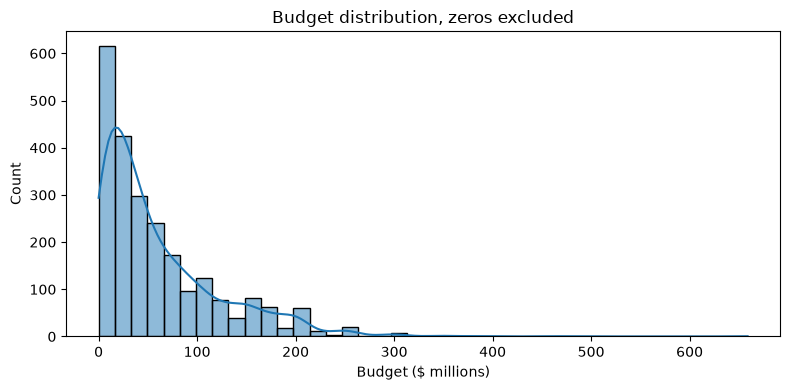

In [2]:
plt.figure(figsize=(8, 4))
sns.histplot(valid["budget"] / 1e6, bins=40, kde=True)
plt.xlabel("Budget ($ millions)")
plt.title("Budget distribution, zeros excluded")
plt.tight_layout()
plt.show()


Budgets pile up at the low end and then stretch out to the right. The median budget, among films that have one reported, is $40 million. The mean is about $61 million because a handful of very expensive films pull it up. A histogram of the raw dollars makes that skew obvious. Most films in this file are not $150 million films.


### Distribution of runtimes


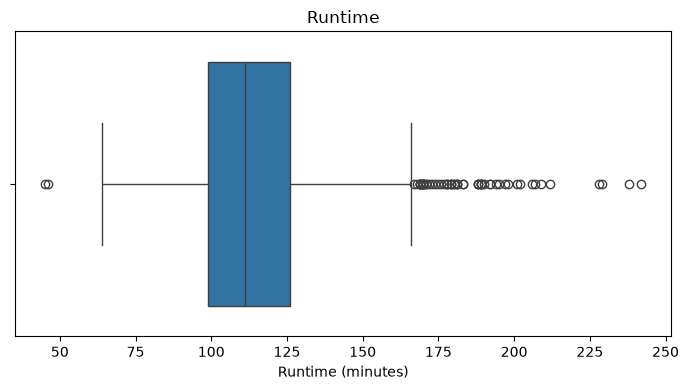

In [3]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=movies["runtime"])
plt.xlabel("Runtime (minutes)")
plt.title("Runtime")
plt.tight_layout()
plt.show()


The box sits roughly between 99 and 126 minutes, with the median at 111. The points to the right are the long films from the IQR check (Justice League at 242, Gone with the Wind, and so on). There are only two points on the short side. Runtime in this dataset is pretty tightly grouped, and the unusual values are almost all "this one is long."


### Distribution of vote_average


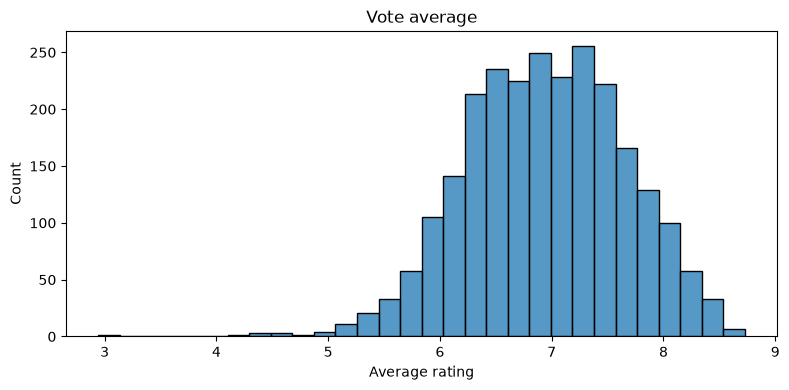

In [4]:
plt.figure(figsize=(8, 4))
sns.histplot(movies["vote_average"], bins=30)
plt.xlabel("Average rating")
plt.title("Vote average")
plt.tight_layout()
plt.show()


Ratings bunch up between about 6.4 and 7.4. The mean is 6.94 and the lowest film in the whole file is still about 2.9, so the left tail barely exists. This is not a sample of every movie ever made. Poorly rated films mostly didn't make it into the extract, and I would not quote this histogram as "audiences rate movies a 7."


### Movies per genre


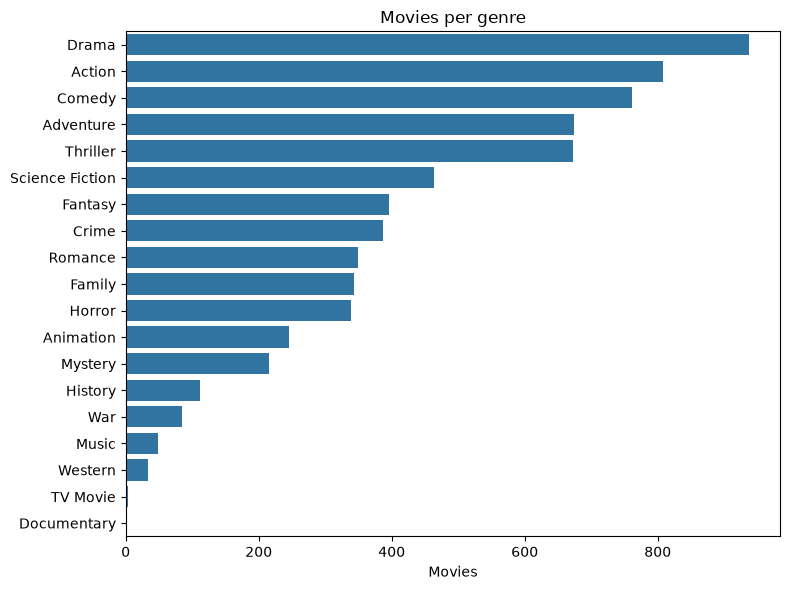

In [5]:
genre_counts = (
    movie_genres.merge(genres, on="genre_id")["genre_name"]
    .value_counts()
    .rename_axis("genre")
    .reset_index(name="n_movies")
)

plt.figure(figsize=(8, 6))
sns.barplot(data=genre_counts, y="genre", x="n_movies", color="C0")
plt.xlabel("Movies")
plt.ylabel("")
plt.title("Movies per genre")
plt.tight_layout()
plt.show()


Drama (937), action (808) and comedy (762) are the big three. A movie with three genres is counted three times, so these bars are not shares of 2,503. Documentary has one film and TV Movie has four. I would not put those two on a slide next to drama and talk about them as genres we "know" something about.


## Bivariate


### Budget vs revenue


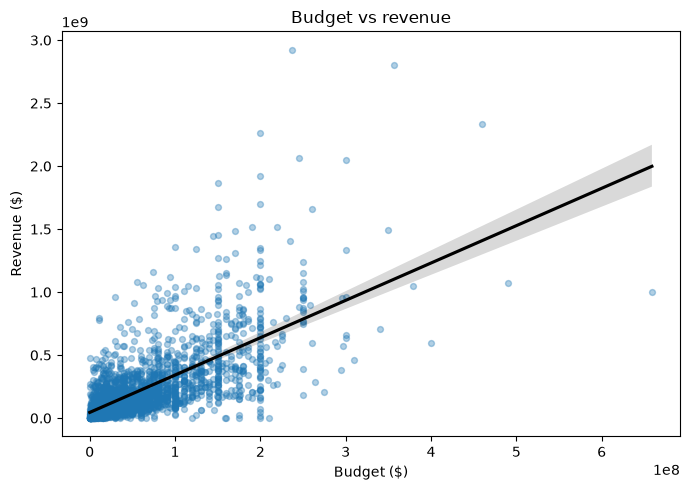

correlation: 0.68


In [6]:
plt.figure(figsize=(7, 5))
sns.regplot(
    data=valid,
    x="budget",
    y="revenue",
    scatter_kws={"alpha": 0.35, "s": 18},
    line_kws={"color": "black"},
)
plt.xlabel("Budget ($)")
plt.ylabel("Revenue ($)")
plt.title("Budget vs revenue")
plt.tight_layout()
plt.show()
print("correlation:", round(valid["budget"].corr(valid["revenue"]), 2))


The line slopes up and the correlation is about 0.68, so bigger budgets and bigger revenues do travel together. The cloud is wide though. Plenty of films sit well above the line and plenty sit below it. A large budget in this data is associated with a larger gross, it does not pin the gross down. Zeros are off this plot, otherwise there would be a fake clump on the axes.


### Popularity vs vote count


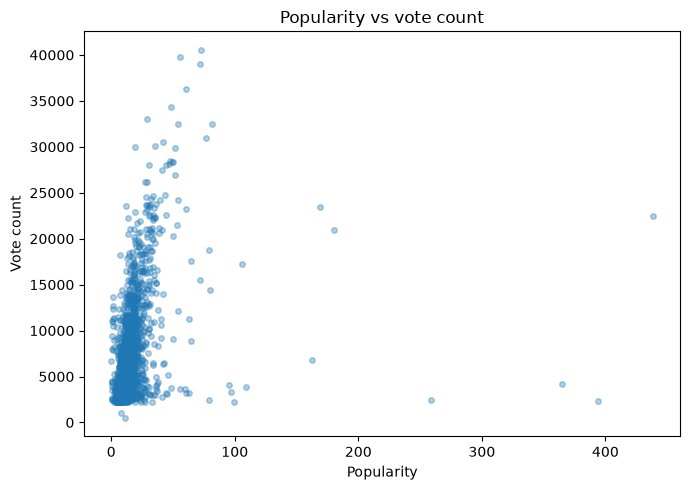

In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(movies["popularity"], movies["vote_count"], alpha=0.35, s=16)
plt.xlabel("Popularity")
plt.ylabel("Vote count")
plt.title("Popularity vs vote count")
plt.tight_layout()
plt.show()


The mass of films sits at modest popularity with a vote count that rises along with it. A few points are far to the right, very high popularity, and they are not always the films with the most votes. That matches the residual check in the pandas notebook: current popularity and lifetime votes are related, but they are not the same measurement. The 2026 titles are the ones that break the pattern most clearly.


### Average rating by genre


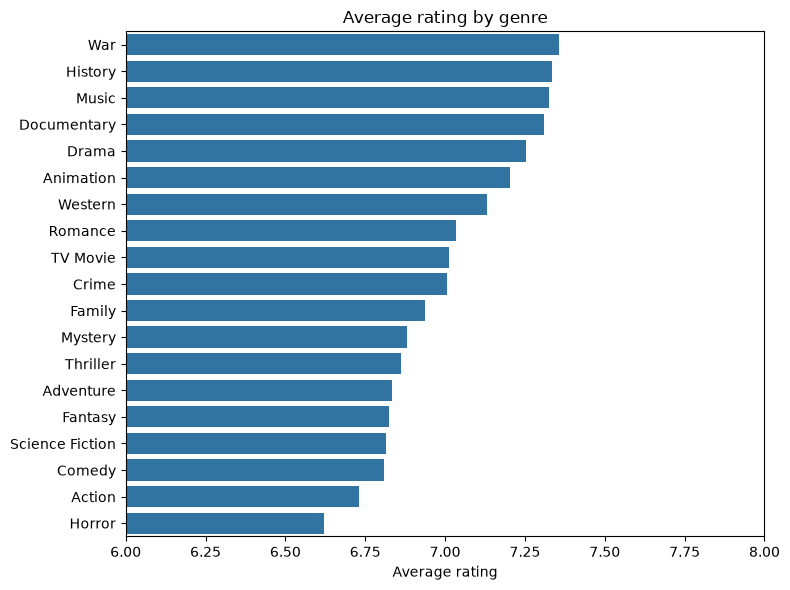

In [8]:
rating_by_genre = (
    movies.merge(movie_genres, on="movie_id")
    .merge(genres, on="genre_id")
    .groupby("genre_name")["vote_average"]
    .mean()
    .sort_values(ascending=False)
    .rename_axis("genre")
    .reset_index(name="avg_rating")
)

plt.figure(figsize=(8, 6))
sns.barplot(data=rating_by_genre, y="genre", x="avg_rating", color="C0")
plt.xlim(6, 8)
plt.xlabel("Average rating")
plt.ylabel("")
plt.title("Average rating by genre")
plt.tight_layout()
plt.show()


I started the x-axis at 6 so the small gaps are visible. War, history, music and drama lead, horror and action are at the bottom. Everything lives between about 6.6 and 7.4. If the axis started at 0, this chart would look like every genre is the same, which is the wrong picture. The differences are real and they are also small. Genre is a weak signal for rating compared with how strong it is for revenue.


### Movies released per year


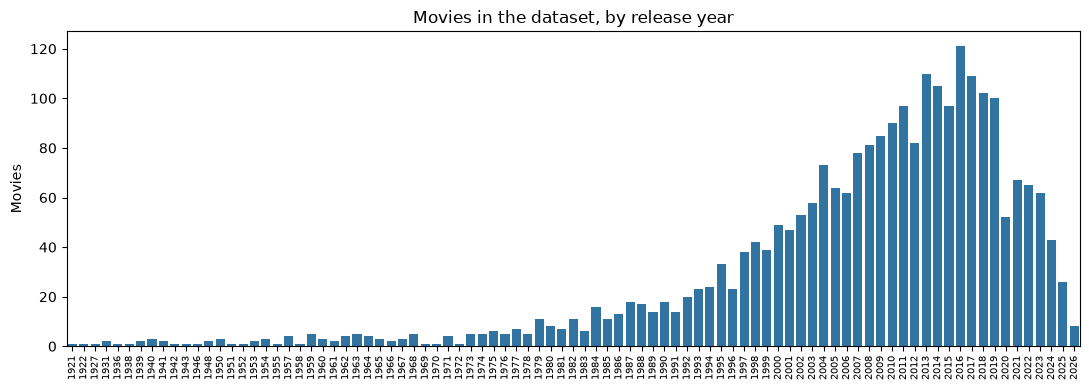

In [9]:
per_year = movies.groupby("year").size().reset_index(name="n_movies")

plt.figure(figsize=(11, 4))
sns.barplot(data=per_year, x="year", y="n_movies", color="C0")
plt.xticks(rotation=90, fontsize=7)
plt.xlabel("")
plt.ylabel("Movies")
plt.title("Movies in the dataset, by release year")
plt.tight_layout()
plt.show()


The bars are short for decades and then jump in the 2000s and 2010s. 2016 is the tallest single year (121 films). Reading this as "the industry peaked in 2016" would be a mistake. It shows how the extract was built: recent, fairly popular films, with older titles only when they are well known.


## Multivariate


### Correlation heatmap


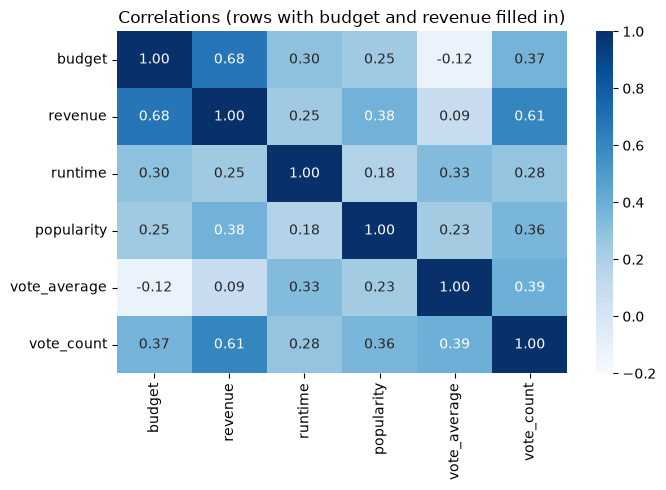

In [10]:
cols = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]
corr = valid[cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=-0.2, vmax=1)
plt.title("Correlations (rows with budget and revenue filled in)")
plt.tight_layout()
plt.show()


Budget and revenue are the strong pair (0.68). Vote count also tracks revenue (0.61), which makes sense if more people seeing a film means both more money and more votes. Budget against vote_average is slightly negative, about -0.12. Spending more is not associated with a higher rating here. Runtime has a mild positive link with rating (0.33), in line with the longer films often being the ones people score highly, but I wouldn't push that very hard.


### Budget vs revenue, colored by primary genre

Eighteen genres on one scatter is unreadable, so I kept the six most common primary genres and labelled the rest "Other". Point size is vote count.


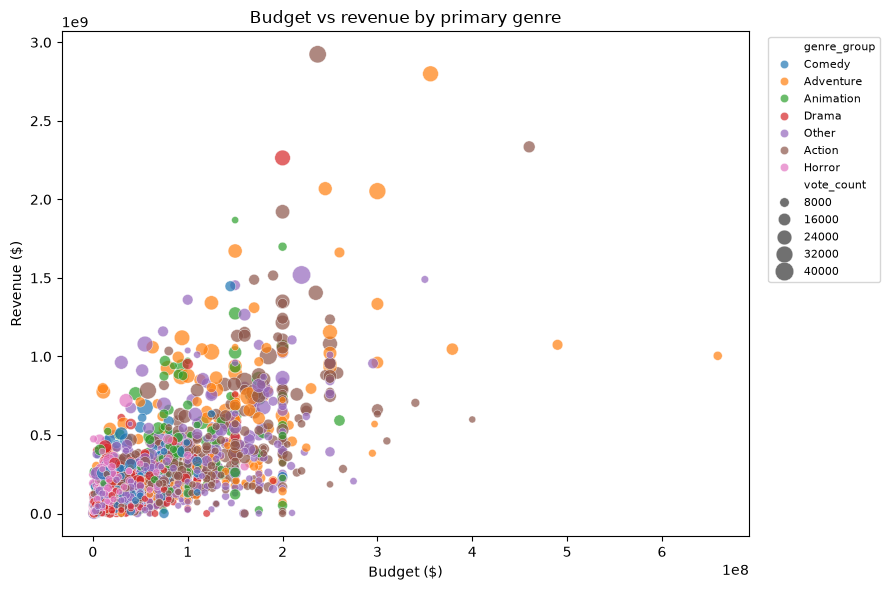

In [11]:
plot_df = valid.merge(first_genre, on="movie_id", how="left")
top_genres = plot_df["genre_name"].value_counts().head(6).index
plot_df["genre_group"] = np.where(
    plot_df["genre_name"].isin(top_genres), plot_df["genre_name"], "Other"
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_df,
    x="budget",
    y="revenue",
    hue="genre_group",
    size="vote_count",
    sizes=(15, 180),
    alpha=0.7,
)
plt.xlabel("Budget ($)")
plt.ylabel("Revenue ($)")
plt.title("Budget vs revenue by primary genre")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


The far upper right, huge budget and huge revenue, is mostly action and adventure. Drama and comedy, which are very common as a primary genre, sit further left and usually lower. The biggest circles (lots of votes) are not always the highest dots. Some mid-budget films have been voted on a lot. Size and height are answering different questions: how many people rated it, versus how much money it reported.


### Average revenue by genre and decade

Decades before 1980 are mostly empty cells in this file, so I started the heatmap at 1980. The color is average revenue for movies that have both budget and revenue. A movie still counts in every genre it belongs to.


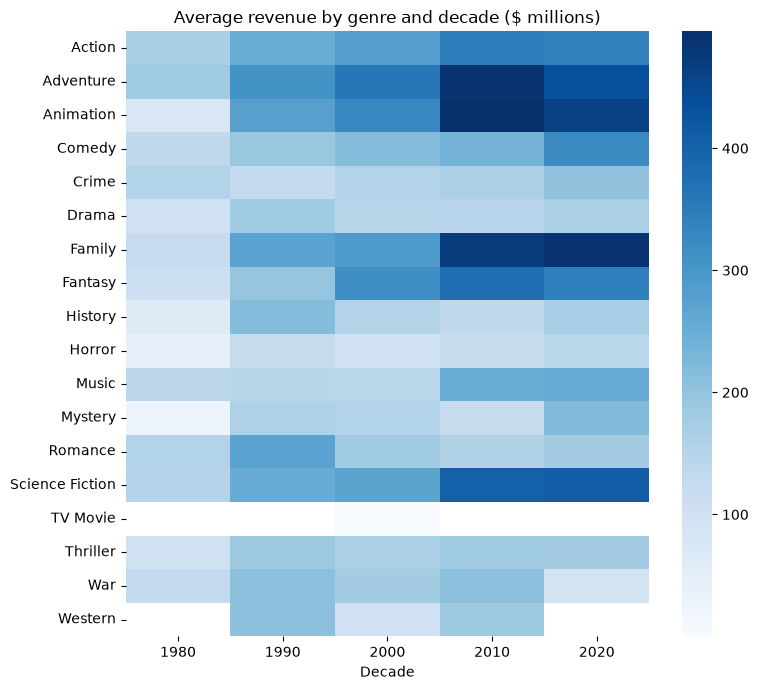

In [12]:
heat = valid.merge(movie_genres, on="movie_id").merge(genres, on="genre_id")
heat["decade"] = (heat["year"] // 10) * 10
heat = heat[heat["decade"] >= 1980]
pivot = heat.pivot_table(
    index="genre_name", columns="decade", values="revenue", aggfunc="mean"
)
# show millions so the color scale is easier to read
pivot_m = pivot / 1e6

plt.figure(figsize=(8, 7))
sns.heatmap(pivot_m, cmap="Blues")
plt.xlabel("Decade")
plt.ylabel("")
plt.title("Average revenue by genre and decade ($ millions)")
plt.tight_layout()
plt.show()


From the 2000s onward the dark cells are adventure, animation and family. Action is high too but not always the darkest. Drama stays lighter across decades, meaning a lower average revenue, even though drama is the most common genre in the bar chart above. The 1980s column is paler almost across the board. Ticket prices and the way this file samples older films both play into that, so I would not say "films made less money in the 80s" from this chart alone.

Putting the charts together: genre tells you more about revenue than about rating, the money fields need the zeros removed before you average them, and the shape of the file (recent, English, already fairly well rated) should be in the first sentence of any conclusion.
